# Neural Machine Translation: English → Gujarati with OpenNMT-py
### Introduction to Large Language Models — Assignment 8

We build an English → Gujarati neural machine translation (NMT) system using
[OpenNMT-py](https://github.com/OpenNMT/OpenNMT-py) and evaluate it with BLEU computed by
[sacreBLEU](https://github.com/mjpost/sacrebleu).

**Data.** The `ilci` subset of [BPCC](https://huggingface.co/datasets/ai4bharat/BPCC)
(Bharat Parallel Corpus Collection, AI4Bharat). For Gujarati this is the file `ilci/guj_Gujr.tsv`
with columns `src_lang, tgt_lang, src, tgt` (`src` = English, `tgt` = Gujarati). The ILCI corpus covers
the health and tourism domains.

**Length-based splits.** Instead of a plain random split, every sentence pair is put in one of 4 bins
by the length (number of whitespace tokens) of its English source sentence, and *both* the train and test
splits are drawn from every bin (stratified sampling), so each split contains sentences of all lengths:

| Bin | Source length $n$ |
|---|---|
| bin1 | $n \le 10$ |
| bin2 | $10 < n \le 20$ |
| bin3 | $20 < n < 30$ |
| bin4 | $n \ge 30$ |

> The assignment writes bin2 as $(10, 20)$ and bin3 as $(20, 30)$. Read as open intervals, sentences of
> length exactly 20 (about 4,300 pairs here) would fall in no bin, so we close bin2 on the right: $(10, 20]$.

**Pipeline.**
1. Download and clean the data, assign length bins, build stratified train / valid / test splits.
2. Learn a SentencePiece subword model for each language.
3. Build vocabularies (`onmt_build_vocab`) and train a Transformer encoder–decoder (`onmt_train`).
4. Translate the test set with beam search (`onmt_translate`).
5. Compute BLEU (and chrF) with sacreBLEU, overall and **per bin**, and analyse the results.

## 0. Setup

Run in the `nlp` conda environment. OpenNMT-py 3.5.1 pins `torch<2.3`; to keep the environment's newer
torch, it is installed with `--no-deps` and its runtime dependencies are added separately.
`pyonmttok==1.37.1` is used because the 1.38.x macOS arm64 wheel is missing its shared library.

In [1]:
# %pip install -q --no-deps OpenNMT-py==3.5.1
# %pip install -q configargparse pyyaml six sacrebleu sentencepiece pyonmttok==1.37.1 huggingface_hub tensorboard rapidfuzz spacy pyahocorasick waitress flask

In [2]:
import os
import re
import sys
import glob
import random
import subprocess
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
# torch >= 2.6 defaults torch.load(weights_only=True), which cannot load OpenNMT-py 3.x checkpoints
os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
import sentencepiece as spm
import sacrebleu
import onmt
from huggingface_hub import hf_hub_download

print("torch", torch.__version__, "| OpenNMT-py", onmt.__version__, "| sacreBLEU", sacrebleu.__version__)

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

SRC_LANG, TGT_LANG = "en", "gu"
BPCC_FILE = "ilci/guj_Gujr.tsv"

DATA_DIR = "lab8_artifacts/data"
SPM_DIR = "lab8_artifacts/spm"
RUN_DIR = "lab8_artifacts/run"
for d in (DATA_DIR, SPM_DIR, RUN_DIR):
    os.makedirs(d, exist_ok=True)

BINS = ["bin1", "bin2", "bin3", "bin4"]
BIN_LABELS = {"bin1": "n ≤ 10", "bin2": "10 < n ≤ 20", "bin3": "20 < n < 30", "bin4": "n ≥ 30"}
TEST_PER_BIN = 1000    # equal-sized test bins so per-bin BLEU scores are comparable
VALID_PER_BIN = 200    # small validation set used by onmt_train for validation / early stopping
VOCAB_SIZE = 8000      # SentencePiece vocabulary per language

USE_GPU = torch.cuda.is_available()   # OpenNMT-py 3.x trains on CUDA or CPU (no MPS backend)
TRAIN_STEPS = 20000
print("CUDA available:", USE_GPU, "| train steps:", TRAIN_STEPS)

torch 2.14.0 | OpenNMT-py 3.5.1 | sacreBLEU 2.6.0
CUDA available: False | train steps: 20000


/opt/anaconda3/envs/nlp/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def run(cmd):
    # Run an OpenNMT-py command line tool with this kernel's interpreter and stream its log.
    print("$", " ".join(cmd))
    proc = subprocess.Popen([sys.executable, "-m"] + cmd, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True, env=os.environ.copy())
    for line in proc.stdout:
        if "Warning" not in line and "@custom_" not in line and "warnings.warn" not in line:
            print(line, end="")
    if proc.wait() != 0:
        raise RuntimeError(f"command failed with exit code {proc.returncode}")

## 1. Load the BPCC `ilci` data

BPCC is a gated dataset: accept its terms on the Hugging Face page and log in once
(`huggingface-cli login`) before running this cell.

In [4]:
tsv_path = hf_hub_download(repo_id="ai4bharat/BPCC", filename=BPCC_FILE, repo_type="dataset")
raw = pd.read_csv(tsv_path, sep="\t", quoting=3, dtype=str, keep_default_na=False)  # quoting=3: QUOTE_NONE
print(raw.shape)
print(raw[["src_lang", "tgt_lang"]].value_counts())
raw.head()

(107385, 4)
src_lang  tgt_lang
eng_Latn  guj_Gujr    107385
Name: count, dtype: int64


,src_lang,tgt_lang,src,tgt
0,eng_Latn,guj_Gujr,What happened?,શું થયું ?
1,eng_Latn,guj_Gujr,What’s the matter?,શું વાત છે ?
2,eng_Latn,guj_Gujr,One gets Moksha with a visit to the Saptapuris !,સપ્તપુરીઓના દર્શનથી મળે છે મોક્ષ .
3,eng_Latn,guj_Gujr,Pilgrimage is of utmost importance in Hinduism .,હિંદુધર્મમાં તીર્થનું ઘણું મહત્ત્વ છે .
4,eng_Latn,guj_Gujr,Although all the pilgrimages are major and imp...,"આમ તો દરેક તીર્થ મહાન અને મહત્ત્વપૂર્ણ છે , પણ..."


### Cleaning

- normalise whitespace and drop empty sides;
- drop exact duplicate pairs, and then duplicate English sentences, so the same source can never be in
  both train and test;
- drop pairs with an extreme length ratio (likely misalignments).

In [5]:
df = raw[["src", "tgt"]].copy()
for c in ("src", "tgt"):
    df[c] = df[c].str.replace(r"\s+", " ", regex=True).str.strip()
df = df[(df.src != "") & (df.tgt != "")]
n0 = len(df)
df = df.drop_duplicates(subset=["src", "tgt"]).drop_duplicates(subset=["src"])
n1 = len(df)

df["src_len"] = df.src.str.split().str.len()
df["tgt_len"] = df.tgt.str.split().str.len()
ratio = df.tgt_len / df.src_len
df = df[(ratio > 1 / 3) & (ratio < 3)].reset_index(drop=True)
print(f"pairs: {n0} -> {n1} after de-duplication -> {len(df)} after length-ratio filter")

pairs: 107385 -> 103042 after de-duplication -> 101497 after length-ratio filter


## 2. Length bins and stratified train / valid / test splits

In [6]:
def length_bin(n):
    if n <= 10:
        return "bin1"
    if n <= 20:
        return "bin2"
    if n < 30:
        return "bin3"
    return "bin4"

df["bin"] = df.src_len.map(length_bin)

parts = {"train": [], "valid": [], "test": []}
for b in BINS:
    g = df[df.bin == b].sample(frac=1.0, random_state=RANDOM_SEED)
    parts["test"].append(g.iloc[:TEST_PER_BIN])
    parts["valid"].append(g.iloc[TEST_PER_BIN:TEST_PER_BIN + VALID_PER_BIN])
    parts["train"].append(g.iloc[TEST_PER_BIN + VALID_PER_BIN:])

splits = {k: pd.concat(v).sample(frac=1.0, random_state=RANDOM_SEED).reset_index(drop=True)
          for k, v in parts.items()}

counts = pd.DataFrame({k: v.bin.value_counts() for k, v in splits.items()}).loc[BINS]
counts.insert(0, "length", [BIN_LABELS[b] for b in BINS])
counts.loc["total"] = ["", *counts[["train", "valid", "test"]].sum()]
counts

,length,train,valid,test
bin,,,,
bin1,n ≤ 10,16983,200,1000
bin2,10 < n ≤ 20,50478,200,1000
bin3,20 < n < 30,21285,200,1000
bin4,n ≥ 30,7951,200,1000
total,,96697,800,4000


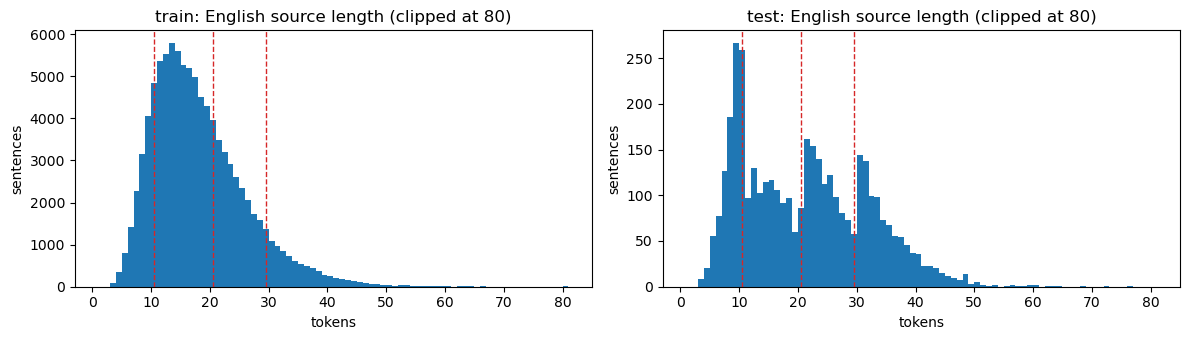

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, name in zip(axes, ["train", "test"]):
    s = splits[name]
    ax.hist(s.src_len.clip(upper=80), bins=range(1, 82), color="tab:blue")
    for edge in (10.5, 20.5, 29.5):
        ax.axvline(edge, color="tab:red", ls="--", lw=1)
    ax.set_title(f"{name}: English source length (clipped at 80)")
    ax.set_xlabel("tokens"); ax.set_ylabel("sentences")
plt.tight_layout(); plt.show()

The training split keeps the natural length distribution of the corpus (most sentences are 10–20
tokens), while the test split has the same number of sentences in each bin so each bin's BLEU is
estimated from the same amount of data.

In [8]:
def write_lines(path, lines):
    with open(path, "w", encoding="utf-8") as f:
        for line in lines:
            f.write(line + "\n")

for name, s in splits.items():
    write_lines(f"{DATA_DIR}/{name}.{SRC_LANG}", s.src)
    write_lines(f"{DATA_DIR}/{name}.{TGT_LANG}", s.tgt)
    write_lines(f"{DATA_DIR}/{name}.bin", s.bin)
print(sorted(os.listdir(DATA_DIR)))

['test.bin', 'test.en', 'test.gu', 'train.bin', 'train.en', 'train.gu', 'valid.bin', 'valid.en', 'valid.gu']


## 3. Subword segmentation (SentencePiece)

A unigram SentencePiece model per language (vocab 8k) is learnt on the training data only. Subwords
keep the vocabulary small and let the model handle rare words and Gujarati's rich morphology
(case markers and postpositions attached to words). OpenNMT-py applies these models on the fly through
its `sentencepiece` transform during training.

In [9]:
for lang in (SRC_LANG, TGT_LANG):
    spm.SentencePieceTrainer.train(
        input=f"{DATA_DIR}/train.{lang}", model_prefix=f"{SPM_DIR}/{lang}",
        vocab_size=VOCAB_SIZE, model_type="unigram", character_coverage=1.0,
        input_sentence_size=1_000_000, shuffle_input_sentence=True, minloglevel=2)

sp_src = spm.SentencePieceProcessor(model_file=f"{SPM_DIR}/{SRC_LANG}.model")
sp_tgt = spm.SentencePieceProcessor(model_file=f"{SPM_DIR}/{TGT_LANG}.model")
ex = splits["train"].iloc[0]
print(ex.src, "\n ->", " ".join(sp_src.encode(ex.src, out_type=str)))
print(ex.tgt, "\n ->", " ".join(sp_tgt.encode(ex.tgt, out_type=str)))

This disease may occur with great speed in the age of 6 to 13 years . 
 -> ▁This ▁disease ▁may ▁occur ▁with ▁great ▁speed ▁in ▁the ▁age ▁of ▁6 ▁to ▁13 ▁years ▁.
૬થી ૧૩ વર્ષની ઉંમરમાં આ બીમારી અચાનક ખૂબ ઝડપથી થઈ શકે છે . 
 -> ▁૬ થી ▁૧૩ ▁વર્ષની ▁ઉંમરમાં ▁આ ▁બીમારી ▁અચાનક ▁ખૂબ ▁ઝડપથી ▁થઈ ▁શકે ▁છે ▁.


## 4. OpenNMT-py configuration

A Transformer encoder–decoder (Vaswani et al., 2017) sized for a ~100k-pair corpus: 4 encoder and
4 decoder layers, model size 256, 4 attention heads, feed-forward size 1024, dropout 0.2, label
smoothing 0.1, Adam with the Noam learning-rate schedule. Separate source/target vocabularies
since the two languages use different scripts. Validation runs every 1000 steps and
training stops early if validation perplexity does not improve for 4 validations.

In [10]:
config = {
    "save_data": f"{RUN_DIR}/samples",
    "src_vocab": f"{RUN_DIR}/vocab.{SRC_LANG}",
    "tgt_vocab": f"{RUN_DIR}/vocab.{TGT_LANG}",
    "overwrite": True,
    "share_vocab": False,
    "data": {
        "corpus_1": {"path_src": f"{DATA_DIR}/train.{SRC_LANG}", "path_tgt": f"{DATA_DIR}/train.{TGT_LANG}",
                     "transforms": ["sentencepiece", "filtertoolong"]},
        "valid": {"path_src": f"{DATA_DIR}/valid.{SRC_LANG}", "path_tgt": f"{DATA_DIR}/valid.{TGT_LANG}",
                  "transforms": ["sentencepiece"]},
    },
    "src_subword_model": f"{SPM_DIR}/{SRC_LANG}.model",
    "tgt_subword_model": f"{SPM_DIR}/{TGT_LANG}.model",
    "src_seq_length": 200,
    "tgt_seq_length": 200,
    "src_vocab_size": VOCAB_SIZE + 100,
    "tgt_vocab_size": VOCAB_SIZE + 100,

    # model
    "model_task": "seq2seq",
    "encoder_type": "transformer",
    "decoder_type": "transformer",
    "enc_layers": 4,
    "dec_layers": 4,
    "hidden_size": 256,
    "word_vec_size": 256,
    "transformer_ff": 1024,
    "heads": 4,
    "position_encoding": True,
    "dropout": [0.2],
    "attention_dropout": [0.1],
    "share_decoder_embeddings": True,

    # optimisation
    "seed": RANDOM_SEED,
    "train_steps": TRAIN_STEPS,
    "valid_steps": 1000,
    "early_stopping": 4,
    "save_model": f"{RUN_DIR}/model",
    "save_checkpoint_steps": 1000,
    "keep_checkpoint": 3,
    "report_every": 200,
    "batch_type": "tokens",
    "batch_size": 4096,
    "valid_batch_size": 2048,
    "accum_count": [1],
    "optim": "adam",
    "adam_beta2": 0.998,
    "decay_method": "noam",
    "learning_rate": 2.0,
    "warmup_steps": 2000,
    "max_grad_norm": 0.0,
    "label_smoothing": 0.1,
    "param_init": 0.0,
    "param_init_glorot": True,
    "normalization": "tokens",
    "bucket_size": 32768,
    "num_workers": 0,
    "world_size": 1,
    "gpu_ranks": [0] if USE_GPU else [],
}

CONFIG_PATH = f"{RUN_DIR}/config.yaml"
with open(CONFIG_PATH, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False, allow_unicode=True)
print(open(CONFIG_PATH).read())

save_data: lab8_artifacts/run/samples
src_vocab: lab8_artifacts/run/vocab.en
tgt_vocab: lab8_artifacts/run/vocab.gu
overwrite: true
share_vocab: false
data:
  corpus_1:
    path_src: lab8_artifacts/data/train.en
    path_tgt: lab8_artifacts/data/train.gu
    transforms:
    - sentencepiece
    - filtertoolong
  valid:
    path_src: lab8_artifacts/data/valid.en
    path_tgt: lab8_artifacts/data/valid.gu
    transforms:
    - sentencepiece
src_subword_model: lab8_artifacts/spm/en.model
tgt_subword_model: lab8_artifacts/spm/gu.model
src_seq_length: 200
tgt_seq_length: 200
src_vocab_size: 8100
tgt_vocab_size: 8100
model_task: seq2seq
encoder_type: transformer
decoder_type: transformer
enc_layers: 4
dec_layers: 4
hidden_size: 256
word_vec_size: 256
transformer_ff: 1024
heads: 4
position_encoding: true
dropout:
- 0.2
attention_dropout:
- 0.1
share_decoder_embeddings: true
seed: 42
train_steps: 20000
valid_steps: 1000
early_stopping: 4
save_model: lab8_artifacts/run/model
save_checkpoint_step

## 5. Build vocabularies

In [11]:
run(["onmt.bin.build_vocab", "-config", CONFIG_PATH, "-n_sample", "-1"])
for lang in (SRC_LANG, TGT_LANG):
    with open(f"{RUN_DIR}/vocab.{lang}", encoding="utf-8") as f:
        print(lang, "vocab size:", sum(1 for _ in f))

$ onmt.bin.build_vocab -config lab8_artifacts/run/config.yaml -n_sample -1
Corpus corpus_1's weight should be given. We default it to 1 for you.
[2026-11-03 13:12:21,452 INFO] Counter vocab from -1 samples.
[2026-11-03 13:12:21,452 INFO] n_sample=-1: Build vocab on full datasets.
[2026-11-03 13:12:25,342 INFO] Counters src: 7997
[2026-11-03 13:12:25,342 INFO] Counters tgt: 7995
[2026-11-03 13:12:25,342 WARNING] path lab8_artifacts/run/vocab.en exists, may overwrite...
[2026-11-03 13:12:25,346 WARNING] path lab8_artifacts/run/vocab.gu exists, may overwrite...
en vocab size: 7997
gu vocab size: 7995


## 6. Train the Transformer

On a CUDA GPU this takes a few minutes; on CPU (OpenNMT-py has no Apple-MPS support) the 20000-step
run takes about three hours on an Apple M4. Training perplexity/accuracy are logged every 200 steps and
validation metrics every 1000 steps.

In [12]:
run(["onmt.bin.train", "-config", CONFIG_PATH])

$ onmt.bin.train -config lab8_artifacts/run/config.yaml
[2026-11-03 13:12:26,588 WARNING] Corpus corpus_1's weight should be given. We default it to 1 for you.
[2026-11-03 13:12:26,588 INFO] Parsed 2 corpora from -data.
[2026-11-03 13:12:26,588 INFO] Get special vocabs from Transforms: {'src': [], 'tgt': []}.
[2026-11-03 13:12:26,599 INFO] The first 10 tokens of the vocabs are:['<unk>', '<blank>', '<s>', '</s>', '▁the', '▁of', '▁.', 's', '▁and', '▁in']
[2026-11-03 13:12:26,599 INFO] The decoder start token is: <s>
[2026-11-03 13:12:26,599 INFO] Building model...
[2026-11-03 13:12:27,247 INFO] Switching model to float32 for amp/apex_amp
[2026-11-03 13:12:27,247 INFO] Non quantized layer compute is fp32
[2026-11-03 13:12:27,248 INFO] NMTModel(
  (encoder): TransformerEncoder(
    (embeddings): Embeddings(
      (make_embedding): Sequential(
        (emb_luts): Elementwise(
          (0): Embedding(8008, 256, padding_idx=1)
        )
        (pe): PositionalEncoding()
      )
      (dropo

In [13]:
log = []
for p in glob.glob(f"{RUN_DIR}/model_step_*.pt"):
    log.append((int(re.search(r"step_(\d+)", p).group(1)), p))
log.sort()
print("checkpoints kept:", [s for s, _ in log])
MODEL_PATH = log[-1][1]
print("using", MODEL_PATH)

checkpoints kept: [18000, 19000, 20000]
using lab8_artifacts/run/model_step_20000.pt


## 7. Translate the test set

The test sources are segmented with the English SentencePiece model, translated with beam search
(beam 5), and the Gujarati output pieces are decoded back to plain text.

In [14]:
test = splits["test"]
src_sp = f"{RUN_DIR}/test.sp.{SRC_LANG}"
pred_sp = f"{RUN_DIR}/pred.sp.{TGT_LANG}"
write_lines(src_sp, (" ".join(sp_src.encode(s, out_type=str)) for s in test.src))

cmd = ["onmt.bin.translate", "-model", MODEL_PATH, "-src", src_sp, "-output", pred_sp,
       "-beam_size", "5", "-batch_size", "2048", "-batch_type", "tokens", "-max_length", "250",
       "-report_time"]
if USE_GPU:
    cmd += ["-gpu", "0"]
run(cmd)

with open(pred_sp, encoding="utf-8") as f:
    hyps = [sp_tgt.decode(line.split()) for line in f.read().splitlines()]
assert len(hyps) == len(test)
test = test.assign(hyp=hyps)
write_lines(f"{RUN_DIR}/pred.{TGT_LANG}", hyps)
test[["bin", "src", "tgt", "hyp"]].head()

$ onmt.bin.translate -model lab8_artifacts/run/model_step_20000.pt -src lab8_artifacts/run/test.sp.en -output lab8_artifacts/run/pred.sp.gu -beam_size 5 -batch_size 2048 -batch_type tokens -max_length 250 -report_time
[2026-11-04 09:47:04,852 INFO] Loading checkpoint from lab8_artifacts/run/model_step_20000.pt
  checkpoint = torch.load(ckpt_path, map_location=torch.device("cpu"))
[2026-11-04 09:47:05,483 INFO] Loading data into the model
[2026-11-04 09:48:02,394 INFO] PRED SCORE: -1.0091, PRED PPL: 2.74 NB SENTENCES: 4000
[2026-11-04 09:48:02,394 INFO] Total translation time (s): 56.9
[2026-11-04 09:48:02,394 INFO] Average translation time (ms): 14.2
[2026-11-04 09:48:02,394 INFO] Tokens per second: 1350.5
Time w/o python interpreter load/terminate:  57.54871916770935


,bin,src,tgt,hyp
0,bin1,Chest remains constricted .,છાતી સંકોચાયેલી રહે છે .,ચાંદર રહે છે .
1,bin4,In the last 2-3 decades changes brought about ...,"છેલ્લા બે - ત્રણ દાયકાઓમાં જીવનશૈલી , ખાન - પા...","છેલ્લા ૨ - ૩ દશકમાં શારીરિક તાણ , તાણ અને તાણન..."
2,bin1,Nose will stop bleeding .,નાકમાંથી લોહી નીકળવાનું બંધ થઈ જશે .,લોહી ક્યારેય બંધ ન કરો .
3,bin4,"On the other side , for ideological battle wit...","ત્યાં , સોવિયેટ સંઘ અને સમાજવાદી દેશના પ્રસારણ...","બીજી બાજુ મીડિયાના જનસંચાર , જનસંચાર અને જનસંચ..."
4,bin3,The arm of the east is extending more towards ...,પૂર્વની ભુજા થોડી વધારે આગળ નીકળેલી છે અને તેન...,પૂર્વના મુખની તરફ વધારે છે અને તેની સામે ઝરૂખા...


## 8. Evaluation with sacreBLEU

Corpus-level BLEU (default `13a` tokenisation, the sacreBLEU standard) is computed on the whole test
set and on each bin separately. We also report chrF, a character n-gram F-score that is more
forgiving of the inflectional variation of Gujarati, the BLEU brevity penalty, and the
hypothesis/reference length ratio.

In [15]:
def scores(frame):
    bleu = sacrebleu.corpus_bleu(list(frame.hyp), [list(frame.tgt)], force=True)  # ILCI text is pre-tokenized
    chrf = sacrebleu.corpus_chrf(list(frame.hyp), [list(frame.tgt)])
    return {"sentences": len(frame), "avg src len": round(frame.src_len.mean(), 1),
            "BLEU": round(bleu.score, 2), "chrF": round(chrf.score, 2),
            "1/2/3/4-gram prec.": "/".join(f"{p:.1f}" for p in bleu.precisions),
            "BP": round(bleu.bp, 3), "hyp/ref len": round(bleu.sys_len / bleu.ref_len, 3)}

rows = {b: {"length": BIN_LABELS[b], **scores(test[test.bin == b])} for b in BINS}
rows["overall"] = {"length": "all", **scores(test)}
results = pd.DataFrame(rows).T
results.to_csv(f"{RUN_DIR}/binwise_results.csv")
bleu_metric = sacrebleu.BLEU(force=True)
print(bleu_metric.corpus_score(list(test.hyp), [list(test.tgt)]))
print("signature:", bleu_metric.get_signature())
results

BLEU = 8.01 37.3/14.7/5.7/2.5 (BP = 0.854 ratio = 0.864 hyp_len = 64469 ref_len = 74644)
signature: nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0


,length,sentences,avg src len,BLEU,chrF,1/2/3/4-gram prec.,BP,hyp/ref len
bin1,n ≤ 10,1000,8.2,14.73,31.94,50.5/26.1/12.5/7.0,0.799,0.817
bin2,10 < n ≤ 20,1000,15.2,9.56,29.1,41.9/18.2/7.4/3.6,0.802,0.819
bin3,20 < n < 30,1000,24.2,7.85,28.06,37.7/14.7/5.7/2.5,0.833,0.846
bin4,n ≥ 30,1000,35.5,5.57,25.73,31.5/10.3/3.5/1.2,0.909,0.913
overall,all,4000,20.8,8.01,27.72,37.3/14.7/5.7/2.5,0.854,0.864


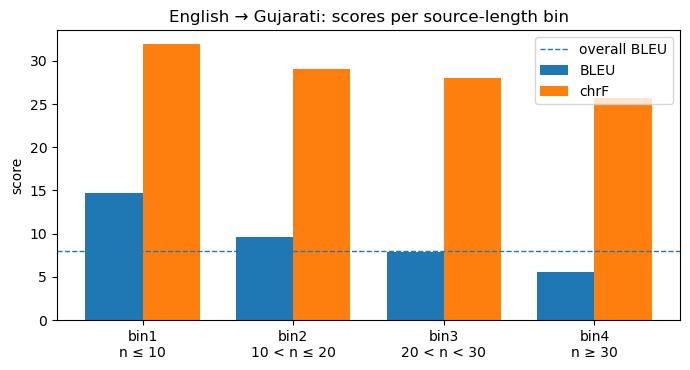

In [16]:
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(BINS))
w = 0.38
ax.bar(x - w / 2, results.loc[BINS, "BLEU"].astype(float), w, label="BLEU", color="tab:blue")
ax.bar(x + w / 2, results.loc[BINS, "chrF"].astype(float), w, label="chrF", color="tab:orange")
ax.axhline(float(results.loc["overall", "BLEU"]), color="tab:blue", ls="--", lw=1, label="overall BLEU")
ax.set_xticks(x, [f"{b}\n{BIN_LABELS[b]}" for b in BINS])
ax.set_ylabel("score"); ax.set_title("English → Gujarati: scores per source-length bin")
ax.legend(); plt.tight_layout(); plt.show()

### Sentence-level BLEU distribution per bin

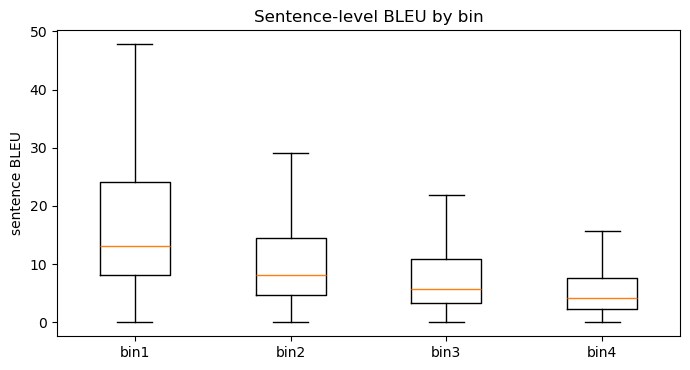

,mean,25%,50%,75%
bin,,,,
bin1,19.5,8.1,13.1,24.2
bin2,11.6,4.6,8.1,14.5
bin3,8.5,3.3,5.7,10.8
bin4,5.9,2.4,4.1,7.7


In [17]:
test["sent_bleu"] = [sacrebleu.sentence_bleu(h, [r]).score for h, r in zip(test.hyp, test.tgt)]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.boxplot([test[test.bin == b].sent_bleu for b in BINS], showfliers=False)
ax.set_xticks(range(1, 5), BINS)
ax.set_ylabel("sentence BLEU"); ax.set_title("Sentence-level BLEU by bin")
plt.tight_layout(); plt.show()
test.groupby("bin").sent_bleu.describe()[["mean", "25%", "50%", "75%"]].round(1)

### Sample translations from each bin

In [18]:
pd.set_option("display.max_colwidth", None)
samples = test.groupby("bin").sample(2, random_state=RANDOM_SEED).sort_values("bin")
for _, r in samples.iterrows():
    print(f"[{r.bin}] sentence BLEU = {r.sent_bleu:.1f}")
    print("  EN :", r.src)
    print("  REF:", r.tgt)
    print("  HYP:", r.hyp, "\n")

[bin1] sentence BLEU = 5.6
  EN : Shahjahan had constructed the beautiful palace named Shahi Bagh .
  REF: શાહીબાગ પેલેસ નામક સુંદર મહેલની રચના શાહજહાંએ કરાવી હતી .
  HYP: શાહજહાંએ સુંદર મહેલનું નિર્માણ કરાવ્યું હતું . 

[bin1] sentence BLEU = 35.1
  EN : This disease can cause damage up to 50-60 percent .
  REF: આ રોગથી ૫૦ - ૬૦ ટકા નુકશાન થઈ શકે છે .
  HYP: આ રોગ ૫૦ - ૬૦ % સુધી થઈ શકે છે . 

[bin2] sentence BLEU = 21.9
  EN : Although there is not much effect of this on the tourists .
  REF: જોકે પર્યટકો પર તેની કોઈ વધારે અસર નથી થતી .
  HYP: જોકે આ પર્યટકો પર વધારે અસર નથી . 

[bin2] sentence BLEU = 3.4
  EN : Those divine journalists do n`t want to turn their camera toward 600 villages of homeless tribals in Chattishgardh .
  REF: એ દેવતા - પત્રકાર છત્તીસગઢમાં ઉજાડવામાં આવેલા આદિવાસીઓના ૬૦૦ ગામ તરફ એમનો કેમેરા વાળવા નથી માંગતા .
  HYP: જે પત્રકાર નથી ઈચ્છતા , તે ૬૦૦ એકરમાં પોતાના ઘરની તરફ વળે છે . 

[bin3] sentence BLEU = 8.1
  EN : Those clients should get tubectomy done after very

## 9. Bin-wise result analysis

| Bin | Source length | BLEU | chrF | 1/2/3/4-gram precision | BP |
|---|---|---|---|---|---|
| bin1 | $n \le 10$ | **14.73** | **31.94** | 50.5 / 26.1 / 12.5 / 7.0 | 0.799 |
| bin2 | $10 < n \le 20$ | 9.56 | 29.10 | 41.9 / 18.2 / 7.4 / 3.6 | 0.802 |
| bin3 | $20 < n < 30$ | 7.85 | 28.06 | 37.7 / 14.7 / 5.7 / 2.5 | 0.833 |
| bin4 | $n \ge 30$ | 5.57 | 25.73 | 31.5 / 10.3 / 3.5 / 1.2 | 0.909 |
| overall | all | 8.01 | 27.72 | 37.3 / 14.7 / 5.7 / 2.5 | 0.854 |

- **Quality drops as sentences get longer.** BLEU falls from 14.73 (bin1) to 5.57 (bin4). All test bins
  have 1,000 sentences, so the bins are directly comparable.
- **Long sentences lose word order, not word choice.** Unigram precision falls mildly (50.5 → 31.5), but
  4-gram precision falls about 6× (7.0 → 1.2). English (SVO) → Gujarati (SOV) needs long-range reordering,
  and errors add up over long sentences. Long sentences are also rare in training (7,951 bin4 pairs
  against 50,478 in bin2).
- **chrF drops much less than BLEU** (−19% vs −62%). It gives partial credit when the stem is right but the
  Gujarati suffix is wrong, so long-sentence translations are closer in meaning than BLEU suggests.
- **Outputs are too short**, especially in bin1 (BP 0.80), where a dropped word or two costs a lot. A
  length penalty at decoding time would help.
- **Errors in long sentences:** repeated words ("ખાંડ, ખાંડ, …"), made-up names, and some misaligned test
  pairs that score ≈0 whatever the output.
- **Longer training helped every bin:** overall BLEU rose from 3.39 at 6k steps to 8.01 at 20k. Bin4 rose
  2.8× (1.99 → 5.57), the biggest relative gain, but the bin ordering stayed the same.

**Conclusion:** BLEU decreases steadily with source length (14.7 → 9.6 → 7.9 → 5.6), mainly because longer
phrases (n-grams) stop matching in long sentences. A single overall BLEU of 8.0 hides this.